# Convolutional Neural Network NILM

## Imports

In [ ]:
import os
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.models import load_model
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2' # Hide Warnings

## Settings

In [58]:
dataset_name = 'ampds_CNN_1week'
model_name = 'cnn_nilm_1week'
batch_size = 32
num_epochs = 50

## Directories 

In [59]:
notebooks_dir = os.getcwd()
base_dir = os.path.join(notebooks_dir, '..')

processed_data_dir = os.path.join(base_dir, 'processed_data')

models_dir = os.path.join(base_dir, 'models')
os.makedirs(models_dir, exist_ok=True)

results_dir = os.path.join(base_dir, 'results')
os.makedirs(results_dir, exist_ok=True)

model_save_filepath = os.path.join(models_dir, model_name + '.keras')

## Load Data

In [60]:
processed_data_filepath = os.path.join(processed_data_dir, dataset_name + '.npz')
data = np.load(processed_data_filepath)

# Check dataset contents
print(f'Dataset Items: {data.files}')

Dataset Items: ['electrical_quantities', 'appliance_names', 'datetimes', 'agg_data', 'apps_data', 'agg_norm', 'apps_norm', 'agg_min', 'agg_max', 'apps_min', 'apps_max', 'train_indices', 'val_indices', 'test_indices', 'train_val_test_split', 'T', 'window_length', 'stride', 'chunk_size', 'num_chunks', 'time_resolution', 'time_units']


In [61]:
electrical_quantities = data['electrical_quantities']
appliance_names = data['appliance_names']

print(f'Electrical Quantities: {electrical_quantities}')
print(f'Appliance Names: {appliance_names}')

Electrical Quantities: ['P-agg' 'I-agg' 'Q-agg' 'S-agg']
Appliance Names: ['HPE' 'FRE']


### Load Normalized and Original Data

In [62]:
p_agg_norm = data['agg_norm'][:, 0] # Keep only P-agg Column
q_agg_norm = data['agg_norm'][:, 2] # Keep only Q-agg Column
p_agg = data['agg_data'][:, 0] # Keep only P-agg Column
q_agg = data['agg_data'][:, 2] # Keep only Q-agg Column

datetimes = data['datetimes']
p_apps_norm = data['apps_norm']
p_apps = data['apps_data']

arrays = {
    "datetimes": datetimes,
    "p_agg_norm": p_agg_norm,
    "q_agg_norm": q_agg_norm,
    "p_agg": p_agg,
    "q_agg": q_agg,
    "p_apps_norm": p_apps_norm,
    "p_apps": p_apps}

for name, data_array in arrays.items():
    df = pd.DataFrame(data_array)
    display(df.head().style.format(precision=2).hide(axis="columns").set_caption(name))

0,60.00
1,120.00
2,180.00
3,240.00
4,300.00


0,0.09
1,0.09
2,0.09
3,0.09
4,0.07


0,0.04
1,0.04
2,0.04
3,0.04
4,0.04


0,875.00
1,870.00
2,829.00
3,829.00
4,731.00


0,141.00
1,141.00
2,139.00
3,141.00
4,140.00


0,0.01,0.02
1,0.02,0.02
2,0.02,0.02
3,0.02,0.02
4,0.01,0.02


0,36.00,106.00
1,37.00,107.00
2,38.00,107.00
3,37.00,106.00
4,36.00,106.00


In [63]:
train_indices = data['train_indices']
val_indices = data['val_indices']
test_indices = data['test_indices']

window_length = data['window_length']

# Scaling Factors
apps_min = data['apps_min']
apps_max = data['apps_max']

## Sample Generation

We use the sequence-to-point model from [citation]. The model takes a window of time-series data as its input, and predicts the target value at a single timestamp, typically at the window's center. In our case, the input is a window of aggregate data, and the output is the appliance-level data at a single timestamp. 

[citation] recognizes that CNNs are designed for and perform well on two-dimensional data. The method converts the real-power series (P) and reactive-power series (Q) into a two-dimensional P-Q signature matrix. The first column represents the real power alone, and the first row represents the reactive power alone. Each element is defined as:

 $S_{xy} = \sqrt{P_x^2 + Q_y^2}$. 

In [64]:
def make_pq_image(p, q):
    
    S = np.zeros((p.size + 1, q.size + 1))
    S[1:, 0] = np.abs(p)
    S[0, 1:] = np.abs(q)
    S[1:, 1:] = np.hypot(p[:, None], q[None, :])
    return S

Each sample consists of an input image and its corresponding target value. The `create_sample` function takes as inputs the entire aggregate real-power and reactive-power time series, as well as the index of the first sample in the window. It then constructs the window. The `targets` is an array consisting of a single target value for each appliance. The function returns both the time-domain image input, and its corresponding appliance power targets.

In [65]:
def create_sample(frame_start_idx, p_agg_norm, q_agg_norm, p_apps_norm, window_length):
    p = p_agg_norm[frame_start_idx : frame_start_idx + window_length]
    q = q_agg_norm[frame_start_idx : frame_start_idx + window_length]
    center_timestep = frame_start_idx + window_length // 2
    targets = p_apps_norm[center_timestep]
    S = make_pq_image(p, q)
    return S, targets

To create a batch, we simply generate samples for a list of window-start indices. Keras expects each input as a single array (a tensor) with a batch dimension in front. So we turn each list of `len(indices)` arrays into one `(len(indices), window_length + 1, window_length + 1)` array. `[..., np.newaxis]` adds a channel axis, giving a new size of `(len(indices), window_length + 1, window_length + 1, 1)`. This sets us up for `Conv2D`, which requires `(batch, height, width, channels)` (a grayscale image has 1 channel). 

In [66]:
def create_batch(indices, p_agg_norm, q_agg_norm, p_apps_norm, window_length):
    S_list, targets_list = [], []
    for i in indices:
        S, targets = create_sample(i, p_agg_norm, q_agg_norm, p_apps_norm, window_length)
        S_list.append(S)
        targets_list.append(targets)
    S_batch = np.stack(S_list)[..., np.newaxis]
    return S_batch, np.array(targets_list)

## Model

This function builds a convolutional neural network (CNN) that takes a $31 \times 31$ single-channel input, and predicts one number per appliance. The input layer has no weights. It's a placeholder that tells Keras the shape of each sample. The batch dimension is left out, so the real tensor shape is `(batch, 31, 31, 1)`.

The 2D convolution layer slides a small window (kernel) across the input. At each position, it takes a weighted sum of the values under the window plus a bias, which produces one number. Each filter learns its own set of weights and detects one kind of local pattern. Early layers pick up simple patterns, while later layers combine those into more complex features. Each filter produces a feature map.

`Flatten()` has no weights. It unrolls the final 3D feature map `(height $\times$ width $\times$ channels)` into a 1D vector so that dense layers can use it. A dense layer is a fully connected layer, where every output is a weighted sum of every input, plus a bias. The dense layers combine all the extracted features. The output layer has a size equal to the number of appliances. It has no activation, so its outputs are linear and can be any real number. 

`compile()` sets up how the model will be trained when we later call `fit()`. 

In [67]:
def create_model_architecture(n_appliances):

    input_layer = layers.Input(shape=(31, 31, 1))

    # Single convolutional branch
    x = layers.Conv2D(30, (10, 10), activation='relu')(input_layer)
    x = layers.Conv2D(30, (8, 8), activation='relu')(x)
    x = layers.Conv2D(40, (6, 6), activation='relu')(x)
    x = layers.Conv2D(50, (5, 5), activation='relu')(x)
    x = layers.Conv2D(50, (5, 5), activation='relu')(x)
    x = layers.Flatten()(x)

    # Dense + Output Layers
    x = layers.Dense(1024, activation='relu')(x)
    out = layers.Dense(n_appliances)(x)   # one output per appliance

     # Model
    model = models.Model(inputs=input_layer, outputs=out)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='mse')

    return model

## Model Training

`train_epoch` runs one full pass over the training data and returns the average training loss. It steps through the `train_indices` (window starting indices) one `batch_size` at a time. For each batch, it creates the input and targets. Then `model.train_on_batch()` runs one gradient step on that batch and returns its loss (MSE). The function averages the batch losses and returns that epoch's mean training loss.

In [68]:
def train_epoch(model, p_agg_norm, q_agg_norm, p_apps_norm, train_indices, window_length, batch_size):

    train_loss, num_batches = 0.0, 0

    for i in tqdm(range(0, len(train_indices), batch_size), desc="Training", leave=False):
        batch_input_indices = train_indices[i : i + batch_size]
        S, targets = create_batch(batch_input_indices, p_agg_norm, q_agg_norm, p_apps_norm, window_length)
        loss = model.train_on_batch(S, targets)
        train_loss += loss
        num_batches += 1

    train_loss /= num_batches
    return train_loss

`validate_epoch` runs one pass over the validation data and returns the average validation loss, without changing the model. It creates inputs and targets similarly to `train_epoch`. `model.test_on_batch()` runs a forward pass and returns the loss (MSE) without updating the weights. The function returns the epoch's mean validation loss.

In [69]:
def validate_epoch(model, p_agg_norm, q_agg_norm, p_apps_norm, val_indices, window_length, batch_size):

    val_loss, num_batches = 0.0, 0

    for i in tqdm(range(0, len(val_indices), batch_size), desc="Validating", leave=False):
        batch_input_indices = val_indices[i : i + batch_size]
        S, targets = create_batch(batch_input_indices, p_agg_norm, q_agg_norm, p_apps_norm, window_length)

        loss = model.test_on_batch(S, targets)
        val_loss += loss
        num_batches += 1

    val_loss /= num_batches
    return val_loss

`train_model` builds a new model and trains it for a given number of epochs, stopping early once validation loss stops improving. When validation loss beats the best seen so far, it records the new best and resets the patience counter. Otherwise the counter goes up, and after 5 epochs in a row without improvement the loop stops. The function returns the trained model, the training loss history, and the validation loss history.

In [70]:
def train_model(p_agg_norm, q_agg_norm, p_apps_norm, train_indices, val_indices,
                window_length, batch_size, num_epochs, patience=5, model_save_filepath=None):

    model = create_model_architecture(n_appliances=p_apps_norm.shape[1])

    best_val_loss = np.inf
    best_weights = None
    patience_counter = 0
    history = {'train_loss': [], 'val_loss': []}

    for epoch in tqdm(range(num_epochs), desc='Epochs'):

        # Shuffle training windows each epoch
        shuffled_train_indices = np.random.permutation(train_indices)

        train_loss = train_epoch(model, p_agg_norm, q_agg_norm, p_apps_norm,
                                 shuffled_train_indices, window_length, batch_size)
        val_loss = validate_epoch(model, p_agg_norm, q_agg_norm, p_apps_norm,
                                  val_indices, window_length, batch_size)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)

        # Early stopping + keep best weights
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = model.get_weights()
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print('Early stopping')
                break

    # Restore best model
    if best_weights is not None:
        model.set_weights(best_weights)

    if model_save_filepath is not None:
        model.save(model_save_filepath)

    return model, history

In [71]:
model, history = train_model(p_agg_norm, q_agg_norm, p_apps_norm, train_indices, val_indices,
                window_length, batch_size, num_epochs, model_save_filepath=model_save_filepath)

Epochs:   0%|          | 0/50 [00:00<?, ?it/s]

Epochs:  22%|██▏       | 11/50 [00:01<00:05,  6.52it/s]

Early stopping


## Inference

The sequence-to-point model returns one value per-appliance per-timestamp. The `predict` function takes as input the normalized aggregate real and reactive power time-series profiles, which are both one-dimensional arrays. It also takes the normalizes appliance power, a two-dimensional array containing time-series data for each appliance. It takes the list of training frame start indices. The function predicts each batch separately, then stacks them into a single prediction array. Negative values are clipped to zero since power can't be negative. The function returns the predicted normalized appliance power.

In [72]:
def predict(model, p_agg_norm, q_agg_norm, p_apps_norm, test_indices, window_length, batch_size):
    apps_pred_all = []

    for i in tqdm(range(0, len(test_indices), batch_size), desc='Predicting'):
        batch_inp = test_indices[i : i + batch_size]
        S, _ = create_batch(
            batch_inp, p_agg_norm, q_agg_norm,
            p_apps_norm, window_length)
        apps_pred_all.append(np.asarray(model.predict_on_batch(S)))

    apps_pred = np.concatenate(apps_pred_all, axis=0)
    return np.clip(apps_pred, 0, None)   # power can't be negative

In [73]:
model = load_model(model_save_filepath)
apps_pred_norm = predict(model, p_agg_norm, q_agg_norm, p_apps_norm, test_indices, window_length, batch_size)

Predicting: 100%|██████████| 2/2 [00:00<00:00, 27.46it/s]


Both the original data and the prediction are ordinary, un-windowed data. However, the arrays don't cover the same timesteps because `p_apps_norm` covers the whole dataset (train + val + test). `appds_pred_norm` only covers timesteps in the testing dataset. To make sure we are comparing the datasets correctly, we first add a datetime column back onto each array.

In [74]:
p_apps_norm_dt = np.column_stack([datetimes, p_apps_norm])

Next we construct a datetimes column for the predicted indices. We use the window length to turn the test indices, which are window start indices, into target indices. We then match these indices to datetimes.

In [75]:
target_indices = test_indices + window_length // 2        # window start -> center (target) timestep
order = np.argsort(target_indices)                        # sort chronologically
pred_datetimes = datetimes[target_indices][order]         # shape (n,)
apps_pred_norm_sorted = apps_pred_norm[order]             # shape (n, n_apps)

apps_pred_norm_dt = pd.DataFrame(apps_pred_norm_sorted)
apps_pred_norm_dt.insert(0, "datetime", pred_datetimes)

Now, we also want un-normalized data. For the ground truth, we still have the original data in our processed dataset. For the predictions, we need to de-normalize using out saved appliance metrics.

In [76]:
p_apps_dt = np.column_stack([datetimes, p_apps])

We need to undo the min-max normalization uses the saved appliance minimum and maximum values from our processed data. 

In [77]:
def unnormalize(data_dt, apps_min, apps_max):
    out = data_dt.copy()
    out = data_dt * (apps_max - apps_min) + apps_min
    return out

In [78]:
# separate datetimes from predictions
pred_datetimes = apps_pred_norm_dt["datetime"].to_numpy()
apps_pred_norm_only = apps_pred_norm_dt.drop(columns="datetime").to_numpy()

# pass through unnormalize function
apps_pred = unnormalize(apps_pred_norm_only, apps_min, apps_max)

# add pred_datetimes back on
apps_pred_dt = pd.DataFrame(apps_pred)
apps_pred_dt.insert(0, "datetime", pred_datetimes)

## Results

### Visualization

In [79]:
def plot_pred_vs_actual(actual_dt, pred_dt, appliance_names, ylabel='Norm. P', title=None):
    """Plot actual vs predicted appliance power over time.
    actual_dt, pred_dt: arrays with Unix-second datetimes in column 0, one appliance per remaining column."""
    actual_dt = np.asarray(actual_dt, dtype=float)
    pred_dt = np.asarray(pred_dt, dtype=float)
    t_true = pd.to_datetime(actual_dt[:, 0], unit='s')
    t_pred = pd.to_datetime(pred_dt[:, 0], unit='s')

    # Restrict actual data to the prediction period so the plots are readable
    mask = (t_true >= t_pred.min()) & (t_true <= t_pred.max())

    app_labels = [str(name).strip() for name in appliance_names]
    n_apps = len(app_labels)

    fig, axes = plt.subplots(n_apps, 1, figsize=(12, 2.2 * n_apps), sharex=True)
    axes = np.atleast_1d(axes)
    for a, ax in enumerate(axes):
        ax.plot(t_true[mask], actual_dt[mask, a + 1], label='Actual', color='black', linewidth=1)
        ax.plot(t_pred, pred_dt[:, a + 1], label='Predicted', color='tab:orange', linewidth=1, alpha=0.8)
        ax.set_title(app_labels[a], fontsize=10, loc='left')
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)

    axes[0].legend(loc='upper right', frameon=False, ncol=2)
    axes[-1].set_xlabel('Time')
    if title:
        fig.suptitle(title)
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

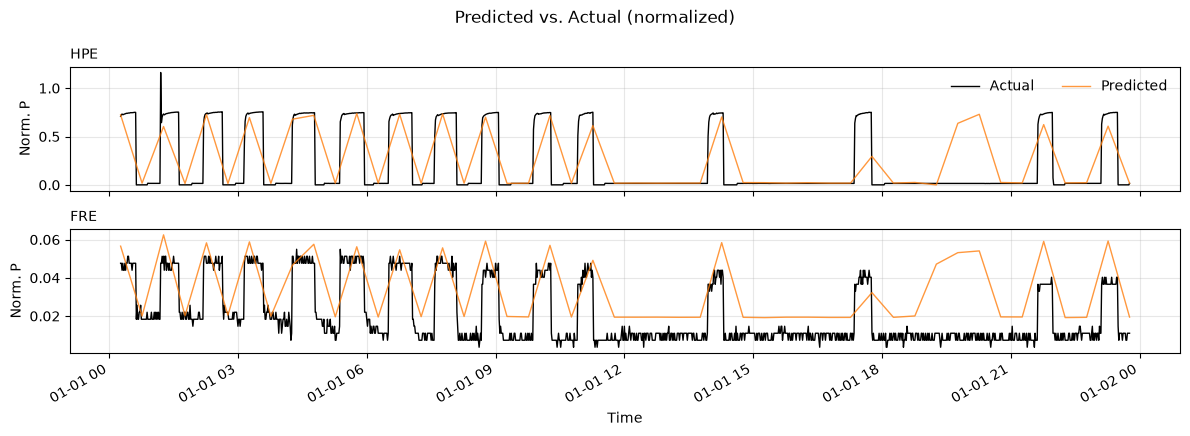

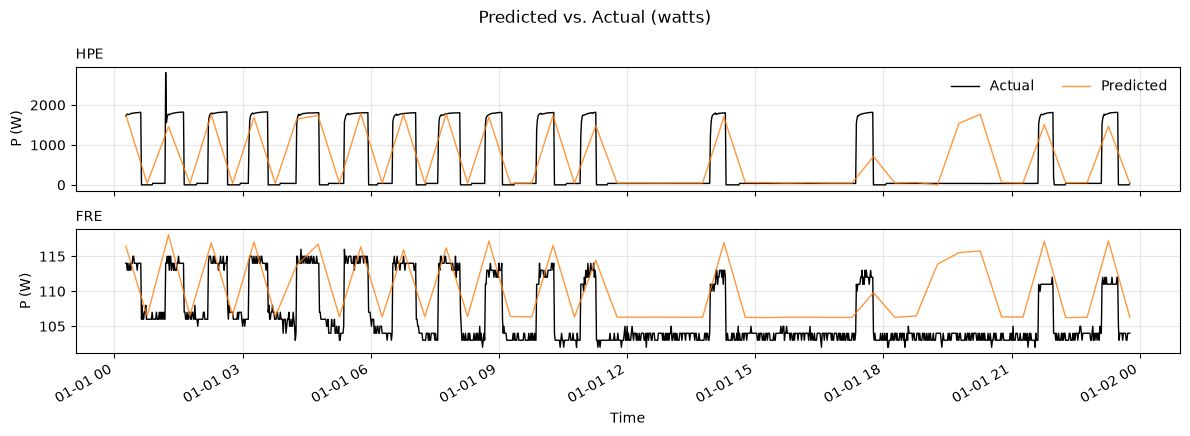

In [51]:
plot_pred_vs_actual(p_apps_norm_dt, apps_pred_norm_dt, appliance_names,
                    ylabel='Norm. P', title='Predicted vs. Actual (normalized)')
plot_pred_vs_actual(p_apps_dt, apps_pred_dt, appliance_names,
                    ylabel='P (W)', title='Predicted vs. Actual (watts)')

### Accuracy Metrics

The primary energy accuracy in NILM literature is estimation accuracy (EACC). Estimation accuracy measures how closely the total predicted energy matches the true energy. It sums the absolute errors over all timesteps and appliances and normalizes them by twice the true total. It was introduced by [CITE 2011 REDD Paper].

$
\text{EACC} = 1 - \frac{\sum_{t=1}^T \sum_{m=1}^K |\hat{y}_t^k - y_t^k|}{2 \sum_{t=1}^T \sum_{m=1}^K y_t^k}
$

- $y_t^k$ = true power of appliance $k$ at time $t$
- $\hat{y}_t^k$ = estimated power of appliance $k$ at time $t$.
- $T$ = total number of timesteps.
- $K$ = total number of appliances.

EACC must be computed on num-normalized power. Min-max scaling rescales each appliance differently, so computed EACC on normalized values will lead to different results.

In [80]:
def compute_eacc(y_true, y_pred):
    return 1 - np.sum(np.abs(y_pred - y_true)) / (2 * np.sum(y_true))

Next we pair each predicted row with the actual row that has the same datetime. `row_idx` is a dict where `row_idx[k]` is the row of `p_apps_dt` that matches prediction row `k`.`y_true = p_apps_dt[row_idx, 1:]` pulls out those matching actual rows and drops the datetime column, leaving only appliance power. `y_pred = apps_pred_dt[:, 1:]` drops the datetime column from the predictions. The result is two arrays with the same shape where row `k` of each refers to the same timestep. 

In [81]:
# where p_apps_norm_dt was built
p_apps_norm_dt = np.column_stack([datetimes, p_apps_norm])

# where apps_pred_norm_dt was built
target_indices = test_indices + window_length // 2
pred_datetimes = datetimes[target_indices]
apps_pred_norm_dt = np.column_stack([pred_datetimes, apps_pred_norm])
apps_pred_norm_dt = apps_pred_norm_dt[np.argsort(apps_pred_norm_dt[:, 0])]

# unnormalize cell (your original slicing works again)
pred_datetimes = apps_pred_norm_dt[:, :1]
apps_pred = unnormalize(apps_pred_norm_dt[:, 1:], apps_min, apps_max)
apps_pred_dt = np.hstack([pred_datetimes, apps_pred])

Next, we compute the overall EACC, as well as the EACC separately for each appliance. 

In [82]:
# Match actual and predicted rows by datetime
actual = np.asarray(p_apps_dt, dtype=float)
pred = np.asarray(apps_pred_dt, dtype=float)
row_idx = np.searchsorted(actual[:, 0], pred[:, 0])
y_true = actual[row_idx, 1:]
y_pred = pred[:, 1:]

eacc = {str(name).strip(): compute_eacc(y_true[:, a], y_pred[:, a])
        for a, name in enumerate(appliance_names)}
eacc['Overall'] = compute_eacc(y_true, y_pred)

In [83]:
eacc_df = pd.DataFrame.from_dict(eacc, orient='index', columns=['EACC'])
display(eacc_df)

,EACC
HPE,0.770485
FRE,0.982000
Overall,0.803830
